Check CO2 emissions for ESM.6 scenarios

In [1]:
import matplotlib.pyplot as plt
import nc_time_axis, cf_units, cftime
import numpy as np
import xarray as xr
import xarray_tools as xrt
import cartopy.crs as ccrs
import iris
from pathlib import Path
from notebook_metadata import create_savefig

savefig = create_savefig(dir='/scratch/tm70/mrd599/plots', nb='check_co2_emissions.ipynb')

In [2]:
from dask.distributed import Client
client = Client(threads_per_worker = 1)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 45615 instead
  warnings.warn(


In [3]:
# Scenarios processed for ESM1.6 so far
scenarios = ["h", "hl", "m", "vl"]
co2_dir = {'hist': Path('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon')}
for s in scenarios:
    co2_dir[s] = Path(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/IIASA-IAMC/IIASA-IAMC-{s}-1-1-1/atmos/mon')

co2_files = {'hist': 'CO2_em_anthro/gn/v20250421/CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc'}
for s in scenarios:
    co2_files[s] = f'CO2_em_anthro/gn/v*/CO2-em-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-{s}-1-1-1_gn_202201-210012.nc'

co2_air_dir = {'hist': Path('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon')}
for s in scenarios:
    co2_air_dir[s] = Path(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/IIASA-IAMC/IIASA-IAMC-{s}-1-1-2/atmos/mon/')

co2_air_files = {'hist': 'CO2_em_AIR_anthro/gn/v20250421/CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc'}
for s in scenarios:
    co2_air_files[s] = f'CO2_em_AIR_anthro/gn/v*/CO2-em-AIR-anthro_input4MIPs_emissions_ScenarioMIP_IIASA-IAMC-{s}-1-1-2_gn_202201-210012.nc'

CO2 = {}
CO2_air = {}
co2_g = {}
co2_air_g = {}
co2_ga_tot = {}
co2_air_ga_tot = {}
co2_air_ga = {}

for run in co2_files:
    files = co2_dir[run].glob(co2_files[run])
    if run == 'hist':
        # Start in 1850
        files = sorted(files)[2:]
    CO2[run] = xr.open_mfdataset(files, chunks={'time':12, 'sector':-1, 'lat':-1, 'lon':-1}).CO2_em_anthro

    files = co2_air_dir[run].glob(co2_air_files[run])
    if run == 'hist':
        # Start in 1850
        files = sorted(files)[2:]
    CO2_air[run] = xr.open_mfdataset(files, chunks={'time':12, 'sector':-1, 'lat':-1, 'lon':-1}).CO2_em_AIR_anthro

area_co2 = xrt.get_area(CO2['hist'])


/jobfs/180075073.gadi-pbs/ipykernel_2637470/370948401.py:32: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  CO2[run] = xr.open_mfdataset(files, chunks={'time':12, 'sector':-1, 'lat':-1, 'lon':-1}).CO2_em_anthro
/jobfs/180075073.gadi-pbs/ipykernel_2637470/370948401.py:38: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  CO2_air[run] = xr.open_mfdataset(files, chunks={'time':12, 'sector':-1, 'lat':-1, 'lon':-1}).CO2_em_AIR_anthro
/jobfs/180075073.gadi-pbs/ipykernel_2637470/370948401.py:38: UserWarning: The specified ch

In [4]:
for run in co2_files:
    print(run)
    co2_g[run] = xrt.global_mean(CO2[run], area_co2).compute()
    co2_air_g[run] = xrt.global_mean(CO2_air[run], area_co2).compute()

    co2_ga_tot[run] = xrt.annual_mean(co2_g[run]).sum('sector').compute()
    co2_air_ga_tot[run] = xrt.annual_mean(co2_air_g[run]).sum('level').compute()
    co2_air_ga[run] = xrt.annual_mean(co2_air_g[run]).compute()


hist
h
hl
m
vl


In [5]:
co2_ga = {}
co2_g_tot = {}
co2_air_g_tot = {}
for run in co2_files:
    co2_ga[run] = xrt.annual_mean(co2_g[run]).compute()
    co2_g_tot[run] = co2_g[run].sum('sector').compute()
    co2_air_g_tot[run] = co2_air_g[run].sum('level').compute()


In [6]:
# Change the calendar to noleap to match input4MIPS
def set_noleap(cube):
    time = cube.coord('time')
    origin = time.units.origin
    newunits = cf_units.Unit(origin, calendar='noleap')

    tvals = np.array(time.points)
    has_bnds = not (time.bounds is None)
    if has_bnds:
        tbnds = np.array(time.bounds)
    for i in range(len(time.points)):
        date = time.units.num2date(tvals[i])
        newdate = cftime.DatetimeNoLeap(date.year, date.month, date.day, date.hour, date.minute, date.second)
        tvals[i] = newunits.date2num(newdate)
        if has_bnds:
            for j in range(2):
                date = time.units.num2date(tbnds[i][j])
                newdate = cftime.DatetimeNoLeap(date.year, date.month, date.day, date.hour, date.minute, date.second)
                tbnds[i][j] = newunits.date2num(newdate)
    time.points = tvals
    if has_bnds:
        time.bounds = tbnds
    time.units = newunits

In [7]:
co2_esm16 = {}
cube = iris.load_cube('/g/data/vk83/configurations/inputs/access-esm1p6/modern/historical-emissions/atmosphere/forcing/global.N96/2026.01.07/CO2_fluxes_1849_2023_cmip7.anc')
set_noleap(cube)
co2_esm16['hist'] = xr.DataArray.from_iris(cube).rename({'latitude':'lat', 'longitude':'lon'})
for s in scenarios:
    cube = iris.load_cube(f'/g/data/tm70/pcl851/CMIP7/esm1p6_ancil/2026.08.14/esm-scenarios/{s}/atmosphere/forcing/global.N96/2026.08.14/CO2_fluxes_{s}_2022_2100_cmip7.anc')
    set_noleap(cube)
    co2_esm16[s] = xr.DataArray.from_iris(cube).rename({'latitude':'lat', 'longitude':'lon'})

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/iris/common/mixin.py:206: FutureWarning: You are using legacy date precision for Iris units - max precision is seconds. In future, Iris will use microsecond precision - available since cf-units version 3.3 - which may affect core behaviour. To opt-in to the new behaviour, set `iris.FUTURE.date_microseconds = True`.
  warnings.warn(message, category=FutureWarning)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/iris/common/mixin.py:206: FutureWarning: You are using legacy date precision for Iris units - max precision is seconds. In future, Iris will use microsecond precision - available since cf-units version 3.3 - which may affect core behaviour. To opt-in to the new behaviour, set `iris.FUTURE.date_microseconds = True`.
  warnings.warn(message, category=FutureWarning)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/iris/common/m

In [8]:
area_esm15 = xr.open_dataset('/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5/piControl/r1i1p1f1/fx/areacella/gn/latest/areacella_fx_ACCESS-ESM1-5_piControl_r1i1p1f1_gn.nc').areacella

In [9]:
co2_esm16_g = {}
for s in co2_esm16:
    co2_esm16_g[s] = xrt.global_mean(co2_esm16[s], area_esm15).compute()

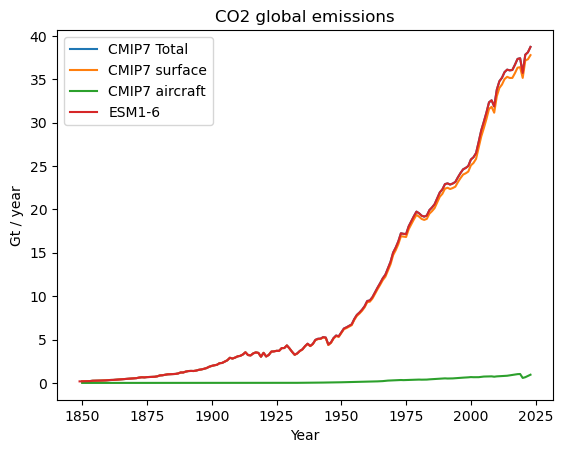

In [10]:
scale = 4 * np.pi * 6.371e6**2 * 365 * 86400 * 1e-12  # Gt/year

fig, axes = plt.subplots()
(scale*(co2_ga_tot['hist']+co2_air_ga_tot['hist'])).plot(label='CMIP7 Total')
(scale*co2_ga_tot['hist']).plot(label='CMIP7 surface')
(scale*co2_air_ga_tot['hist']).plot(label='CMIP7 aircraft')
(scale*xrt.annual_mean(co2_esm16_g['hist'])).plot(label='ESM1-6')
axes.legend()
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('CO2 global emissions')
# axes.set_xlim(2000,2015)
# axes.set_ylim(1.5e-9,2.3e-9)
savefig('co2_emissions.png')

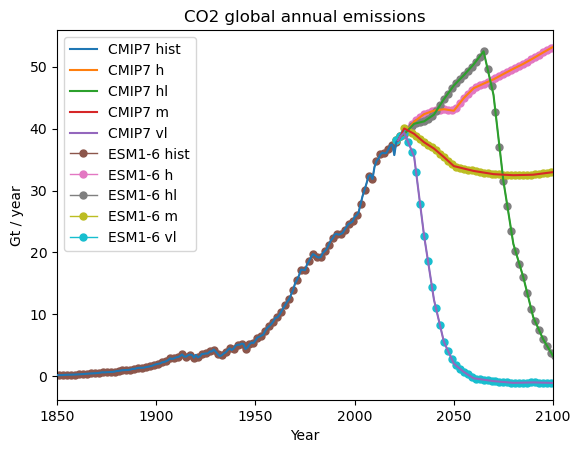

In [11]:
scale = 4 * np.pi * 6.371e6**2 * 365 * 86400 * 1e-12  # Gt/year

fig, axes = plt.subplots()
for s in co2_ga_tot:
    (scale*(co2_ga_tot[s]+co2_air_ga_tot[s])).plot(label=f'CMIP7 {s}', zorder=100)
for s in co2_ga_tot:
    (scale*xrt.annual_mean(co2_esm16_g[s])).plot(label=f'ESM1-6 {s}', lw=1, marker='o', markersize=5, markevery=2)
axes.legend()
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('CO2 global annual emissions')
axes.set_xlim(1850,2100)
# axes.set_ylim(1.5e-9,2.3e-9)
savefig('co2_emissions.png')

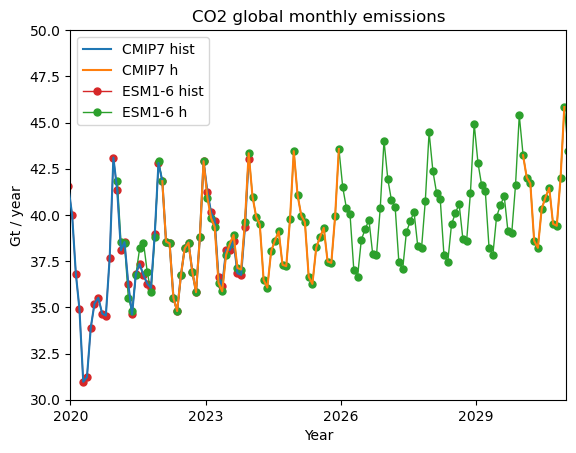

In [12]:
scale = 4 * np.pi * 6.371e6**2 * 365 * 86400 * 1e-12  # Gt/year

fig, axes = plt.subplots()
s = 'hist'
(scale*(co2_g_tot[s]+co2_air_g_tot[s])).plot(label=f'CMIP7 {s}', zorder=100)
s = 'h'
(scale*(co2_g_tot[s]+co2_air_g_tot[s])).sel(time=slice("2022", "2025")).plot(label=f'CMIP7 {s}', zorder=100)
(scale*(co2_g_tot[s]+co2_air_g_tot[s])).sel(time="2030").plot(zorder=100, color='C1')
s = 'hist'
(scale*co2_esm16_g[s]).plot(label=f'ESM1-6 {s}', lw=1, marker='o', markersize=5, markevery=1, color='C3')
s = 'h'
(scale*co2_esm16_g[s]).plot(label=f'ESM1-6 {s}', lw=1, marker='o', markersize=5, markevery=1, color='C2')
axes.legend()
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('CO2 global monthly emissions')
taxis = cf_units.Unit("days since 2000-01-01 00:00", calendar="noleap")
t0 = taxis.date2num(cftime.DatetimeNoLeap(2020,1,1,0,0,0))
t1 = taxis.date2num(cftime.DatetimeNoLeap(2031,1,1,0,0,0))
axes.set_xlim(t0,t1)
axes.set_ylim(30,50)
# axes.set_xlim(2020,2030)
# axes.set_ylim(1.5e-9,2.3e-9)
savefig('co2_monthly_emissions.png')

In [13]:
scale = 86400 * 365
co2_esm16_2050 = {}
co2_esm16_2100 = {}
co2_2050 = {}
co2_2100 = {}
for s in ["h", "hl", "m", "vl"]:
    co2_esm16_2050[s] = scale*xrt.annual_mean(co2_esm16[s].sel(time="2050"))
    co2_esm16_2100[s] = scale*xrt.annual_mean(co2_esm16[s].sel(time="2100"))
    co2_2050[s] = scale*xrt.annual_mean(CO2[s].sel(time="2050").sum('sector')+CO2_air[s].sel(time="2050").sum("level"))
    co2_2100[s] = scale*xrt.annual_mean(CO2[s].sel(time="2100").sum('sector')+CO2_air[s].sel(time="2100").sum("level"))

In [14]:
for s in ["h", "hl", "m", "vl"]:
    print(s)
    print(f'{co2_2050[s].min().values:e} {co2_2050[s].max().values:e}')
    print(f'{co2_esm16_2050[s].min().values:e} {co2_esm16_2050[s].max().values:e}')

h
-3.364789e-03 1.242597e+02
-2.314903e-08 1.350107e+01
hl
-7.136739e-03 1.253443e+02
-2.220470e-03 1.729840e+01
m
0.000000e+00 9.577699e+01
0.000000e+00 9.091645e+00
vl
-3.130314e+00 8.333653e+00
-4.859274e-01 1.489957e+00


In [15]:
for s in ["h", "hl", "m", "vl"]:
    print(s)
    print(f'{co2_2100[s].min().values:e} {co2_2100[s].max().values:e}')
    print(f'{co2_esm16_2100[s].min().values:e} {co2_esm16_2100[s].max().values:e}')

h
0.000000e+00 1.713612e+02
0.000000e+00 2.021307e+01
hl
-2.323305e+00 4.152872e+01
-5.615999e-01 6.197074e+00
m
0.000000e+00 2.028598e+02
0.000000e+00 2.830802e+01
vl
-1.001782e+00 7.441778e+00
-5.039647e-01 7.826723e-01


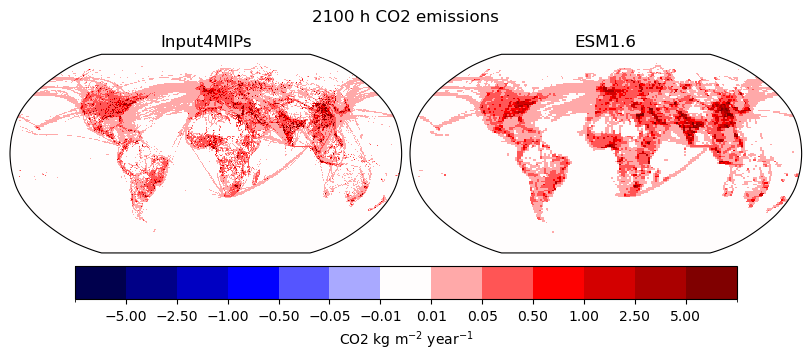

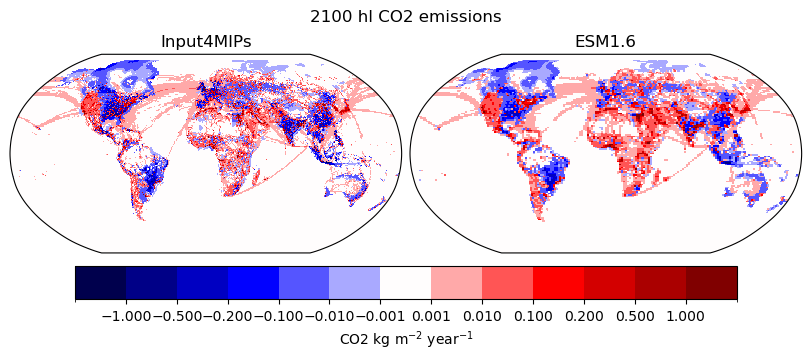

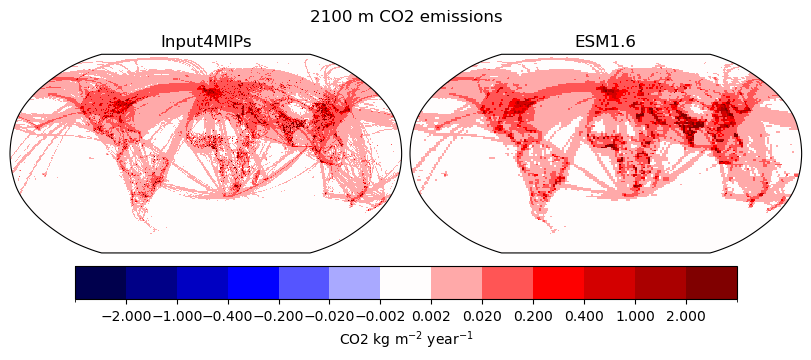

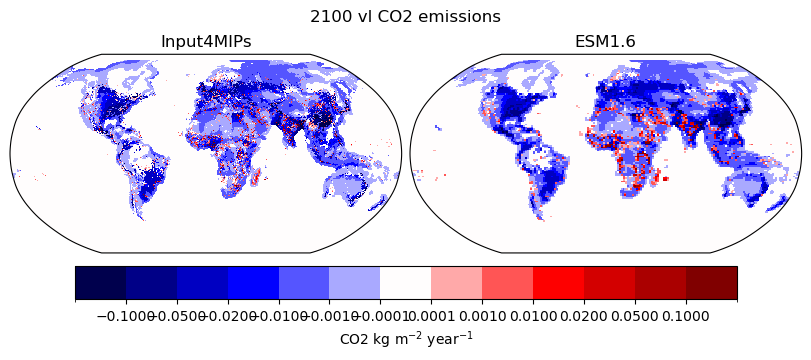

2026-09-29 11:55:40,152 - distributed.worker - ERROR - Failed to communicate with scheduler during heartbeat.
Traceback (most recent call last):
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/comm/tcp.py", line 226, in read
    frames_nosplit_nbytes_bin = await stream.read_bytes(fmt_size)
                                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tornado.iostream.StreamClosedError: Stream is closed

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/worker.py", line 1273, in heartbeat
    response = await retry_operation(
               ^^^^^^^^^^^^^^^^^^^^^^
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/utils_comm.py", line 416, in retry_operation
    return await retry(
           ^^^^^^^^^^^^
  File "/g/d

In [16]:
alevels = np.array([-100, -1., -0.5, -0.2, -0.1, -0.01, 0., 0.01,  0.1,  0.2, 0.5, 1., 100])
alevels = np.array([-100., -1., -0.5, -0.2, -0.1, -0.01, -0.001, 0.001, 0.01,  0.1,  0.2, 0.5, 1., 100.])
scale = {'h': 5, 'hl':1, 'm':2, 'vl':0.1}
cmap = 'seismic'
for s in ["h", "hl", "m", "vl"]:
    fig, axes = plt.subplots(1,2,layout='constrained', figsize=(8,3.5), subplot_kw={'projection': ccrs.Robinson()})
    axes = axes.flatten()
    levels = scale[s] * alevels
    fig.suptitle(f'2100 {s} CO2 emissions')
    # Do this first because the input4mips misses white in the middle for some reason
    ax = axes[1]
    p = co2_esm16_2100[s].plot(ax=ax,transform=ccrs.PlateCarree(), add_colorbar=False, levels=levels, cmap=cmap)
    ax.set_title(f'ESM1.6')

    cbar = fig.colorbar(p, ax=axes, orientation='horizontal', extend='neither', ticks=levels[1:-1])
    cbar.set_label(label='CO2 kg m$^{-2}$ year$^{-1}$')

    ax = axes[0]
    co2_2100[s].plot(ax=ax,transform=ccrs.PlateCarree(), add_colorbar=False, levels=levels, colors=p.colorbar.cmap.colors)
    ax.set_title(f'Input4MIPs')

    savefig(f'co2_2100_{s}.png')